# EDA: Telco Customer Churn

**Автор:** Семенов Вадим, команда 2, кейс 2  
**Дата:** 2026-11-10

Первичный разведочный анализ датасета оттока абонентов телеком-оператора. Цель — определить характеристики, услуги, условия договора и платежи, связанные с оттоком `Churn`, и сформулировать гипотезы для моделирования. Связь признака с оттоком не трактуем как причинность.

План соответствует `docs/eda-plan.md`.

---

## 1. Загрузка и первый взгляд на данные

### 📋 Описание полей датасета

Одна строка = один абонент, 21 поле.

**Идентификатор:** `customerID` — уникальный ID клиента, служебное поле (не признак).

**Демография:**
- `gender` — пол (Female / Male);
- `SeniorCitizen` — признак пенсионного возраста (1 / 0);
- `Partner` — наличие партнёра (Yes / No);
- `Dependents` — наличие иждивенцев (Yes / No).

**Договор:** `tenure` — срок пользования услугами в месяцах; `Contract` — тип договора (Month-to-month / One year / Two year); `PaperlessBilling` — безбумачное выставление счётов (Yes / No).

**Телефония:** `PhoneService` — подключена телефония; `MultipleLines` — несколько линий (Yes / No / No phone service).

**Интернет и онлайн-услуги** (значение `No internet service` — интернет не подключён):
`InternetService` (DSL / Fiber optic / No), `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`.

**Платежи:** `PaymentMethod` — способ оплаты (Electronic check / Mailed check / Bank transfer / Credit card); `MonthlyCharges` — текущая ежемесячная плата; `TotalCharges` — суммарные начисления за всё время.

**Целевая переменная:** `Churn` — ушёл ли клиент (Yes / No).


In [1]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


In [2]:
# Загрузка датасета (источник: Kaggle, IBM HR Analytics — Telco Customer Churn)
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.shape

(7043, 21)

In [3]:
# Первые 5 строк
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Случайная выборка — всегда смотрим разные срезы
df.sample(5, random_state=42)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,No,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


In [5]:
# Технический паспорт данных
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Все поля читаются как `object`, хотя `SeniorCitizen`, `tenure`, `MonthlyCharges` и `TotalCharges` — числовые. Одна строка = один абонент (`customerID`).

In [6]:
# Сводка по числовым полям (после приведения типов)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[num_cols].describe().round(2)

,tenure,MonthlyCharges
count,7043.00,7043.00
mean,32.37,64.76
std,24.56,30.09
min,0.00,18.25
25%,9.00,35.50
50%,29.00,70.35
75%,55.00,89.85
max,72.00,118.75


---

## 2. Качество данных: дубликаты, пропуски, скрытые пропуски

In [7]:
# Полные дубликаты и повторы customerID
print('Полные дубликаты:', df.duplicated().sum())
print('Повторы customerID:', df['customerID'].duplicated().sum())

Полные дубликаты: 0
Повторы customerID: 0


In [8]:
# Скрытые пропуски: TotalCharges содержит пробелы вместо чисел
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
na_mask = df['TotalCharges'].isna()
print('Скрытые пропуски TotalCharges:', na_mask.sum())
df[na_mask][['customerID', 'tenure', 'Contract', 'MonthlyCharges', 'Churn']]

Скрытые пропуски TotalCharges: 11


,customerID,tenure,Contract,MonthlyCharges,Churn
488,4472-LVYGI,0,Two year,52.55,No
753,3115-CZMZD,0,Two year,20.25,No
936,5709-LVOEQ,0,Two year,80.85,No
1082,4367-NUYAO,0,Two year,25.75,No
1340,1371-DWPAZ,0,Two year,56.05,No
3331,7644-OMVMY,0,Two year,19.85,No
3826,3213-VVOLG,0,Two year,25.35,No
4380,2520-SGTTA,0,Two year,20.00,No
5218,2923-ARZLG,0,One year,19.70,No
6670,4075-WKNIU,0,Two year,73.35,No


### Решение по 11 пробельным значениям

Все 11 строк — новые абоненты (`tenure = 0`), у них ещё не было начислений, поэтому `TotalCharges` пустое. Это логичные нули, а не ошибки: заполняем нулём и **не удаляем** строки — они валидные клиенты с потенциальным оттоком.

In [9]:
# Заполняем пропуски нулями и оптимизируем память через категориальные типы
df['TotalCharges'] = df['TotalCharges'].fillna(0)

cat_cols = df.select_dtypes('object').columns.drop(['customerID', 'Churn'])
df[cat_cols] = df[cat_cols].astype('category')
df['SeniorCitizen'] = df['SeniorCitizen'].astype('category')  # бинарный флаг, не число
df['Churn'] = df['Churn'].astype('category')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   str     
 1   gender            7043 non-null   category
 2   SeniorCitizen     7043 non-null   category
 3   Partner           7043 non-null   category
 4   Dependents        7043 non-null   category
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   category
 7   MultipleLines     7043 non-null   category
 8   InternetService   7043 non-null   category
 9   OnlineSecurity    7043 non-null   category
 10  OnlineBackup      7043 non-null   category
 11  DeviceProtection  7043 non-null   category
 12  TechSupport       7043 non-null   category
 13  StreamingTV       7043 non-null   category
 14  StreamingMovies   7043 non-null   category
 15  Contract          7043 non-null   category
 16  PaperlessBilling  7043 non-null   c

C:\Users\55873\AppData\Local\Temp\ipykernel_43316\4197685670.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes('object').columns.drop(['customerID', 'Churn'])


---

## 3. Целевая переменная: распределение оттока

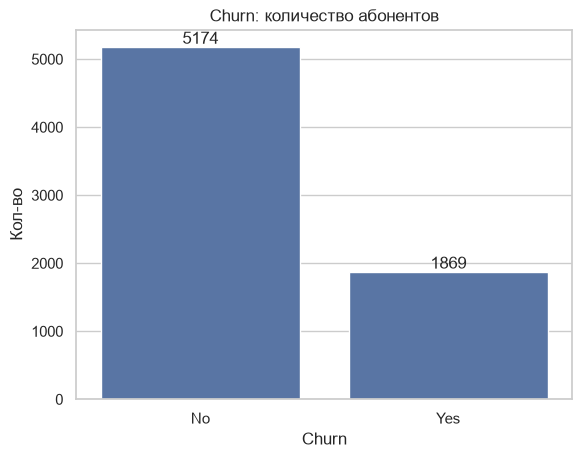

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [10]:
# Распределение Churn: количество и доля классов
churn = df['Churn'].value_counts()
ax = sns.barplot(x=churn.index, y=churn.values)
ax.bar_label(ax.containers[0])
plt.title('Churn: количество абонентов')
plt.ylabel('Кол-во')
plt.show()
print((df['Churn'].value_counts(normalize=True) * 100).round(1))

### **Вывод:** классы несбалансированы — 26,5% ушедших и 73,5% оставшихся. Для моделирования понадобятся метрики, устойчивые к дисбалансу (ROC-AUC, PR-AUC, F1), а возможно и балансировка выборки.

---

## 4. Одномерный анализ признаков

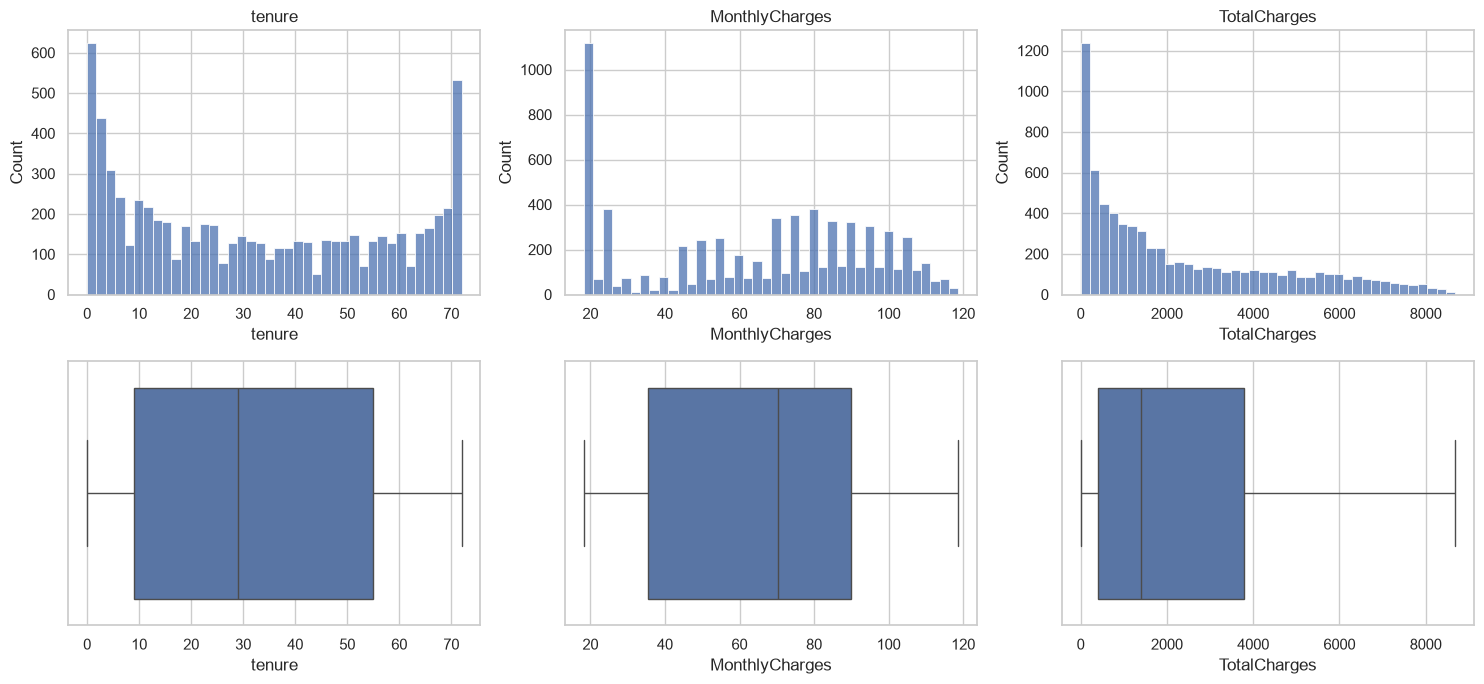

tenure              29.00
MonthlyCharges      70.35
TotalCharges      1394.55
dtype: float64


In [11]:
# Числовые признаки: гистограммы и boxplot
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=40, ax=axes[0, i]).set_title(col)
    sns.boxplot(x=df[col], ax=axes[1, i])
plt.tight_layout()
plt.show()
print(df[num_cols].median())

### **Наблюдения:**
- `tenure` — U-образное распределение: много новых и много долгоживущих абонентов.
- `MonthlyCharges` — пик в районе 20 (дешёвые тарифы только с телефонией).
- `TotalCharges` растёт с `tenure`, скошено вправо — ожидаемо для накопительного признака.
- Формальных выбросов по IQR нет; экстремальные значения объясняются смыслом данных, удалять не будем.

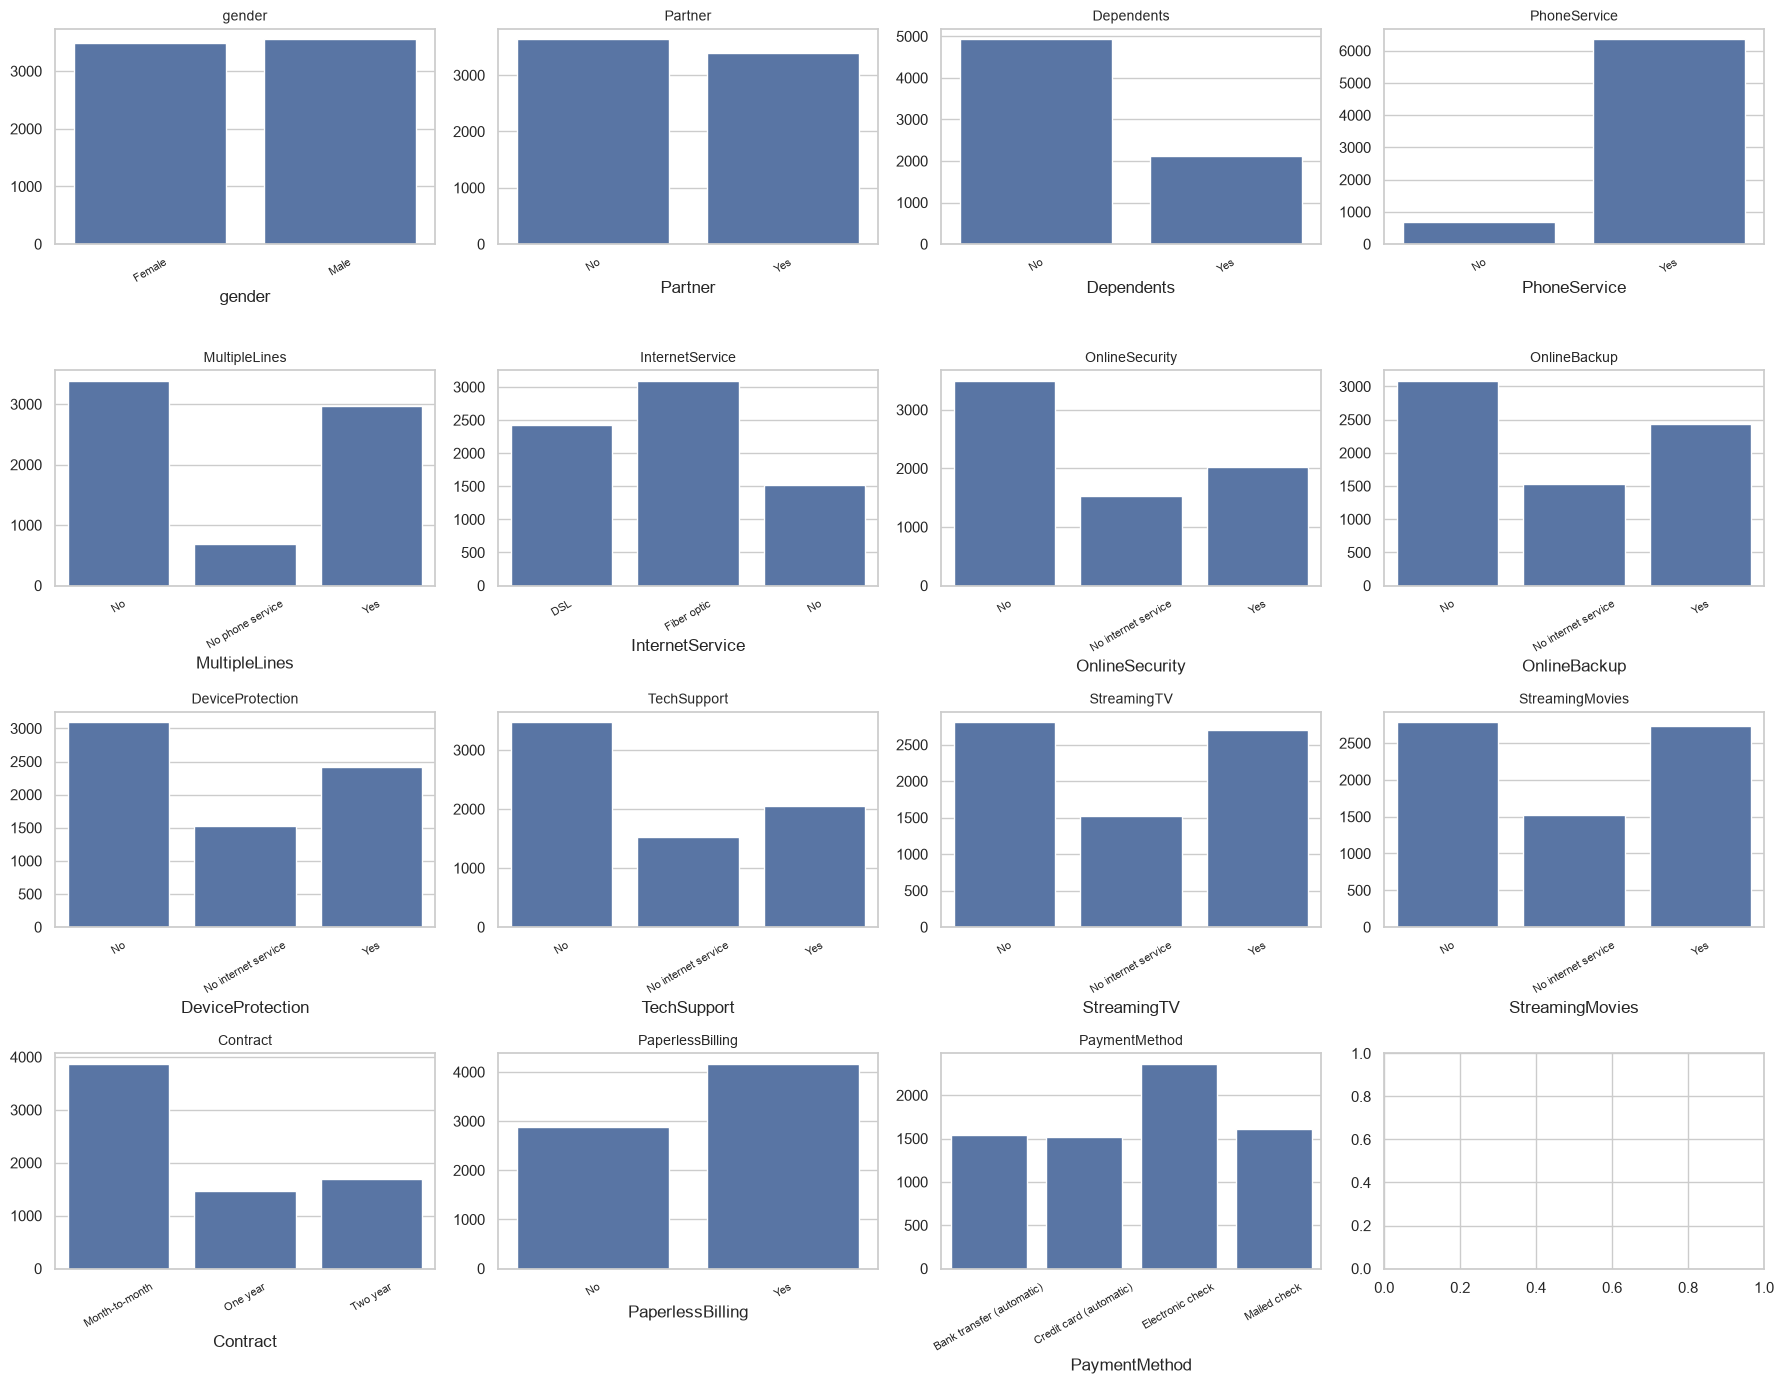

In [12]:
# Категориальные признаки: частоты
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, cat_cols):
    counts = df[col].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
plt.tight_layout()
plt.show()

### **Наблюдения:** баланс полов, треть — пожилые абоненты без партнёра и иждивенцев; около половины пользуются интернетом; долгосрочных контрактов (Two year) заметно меньше, чем помесячных.

---

## 5. Сравнение групп оттока (Churn = Yes vs No)

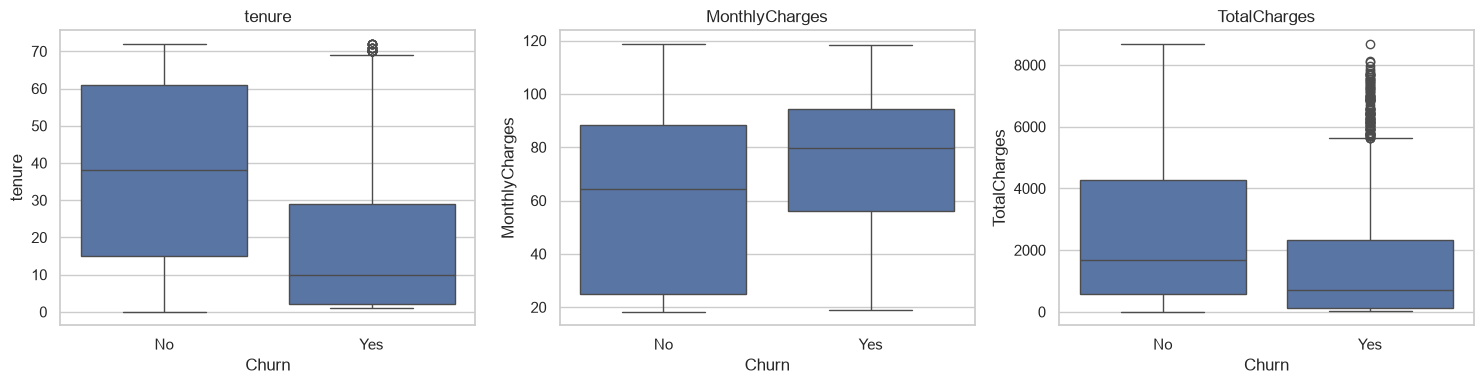

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.4,1679.5
Yes,10.0,79.6,703.6


In [13]:
# Числовые признаки по группам оттока
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df['Churn'], y=df[col], ax=ax).set_title(col)
plt.tight_layout()
plt.show()

# Таблица медиан по группам
df.groupby('Churn')[num_cols].median().round(1)

### **Наблюдения:** ушедшие платили заметно больше в месяц при меньшем сроке жизни — это «новые и дорогие» клиенты. Разница медиан `MonthlyCharges` (74,4 vs 64,8) и `tenure` (10 vs 38 мес.) существенна.

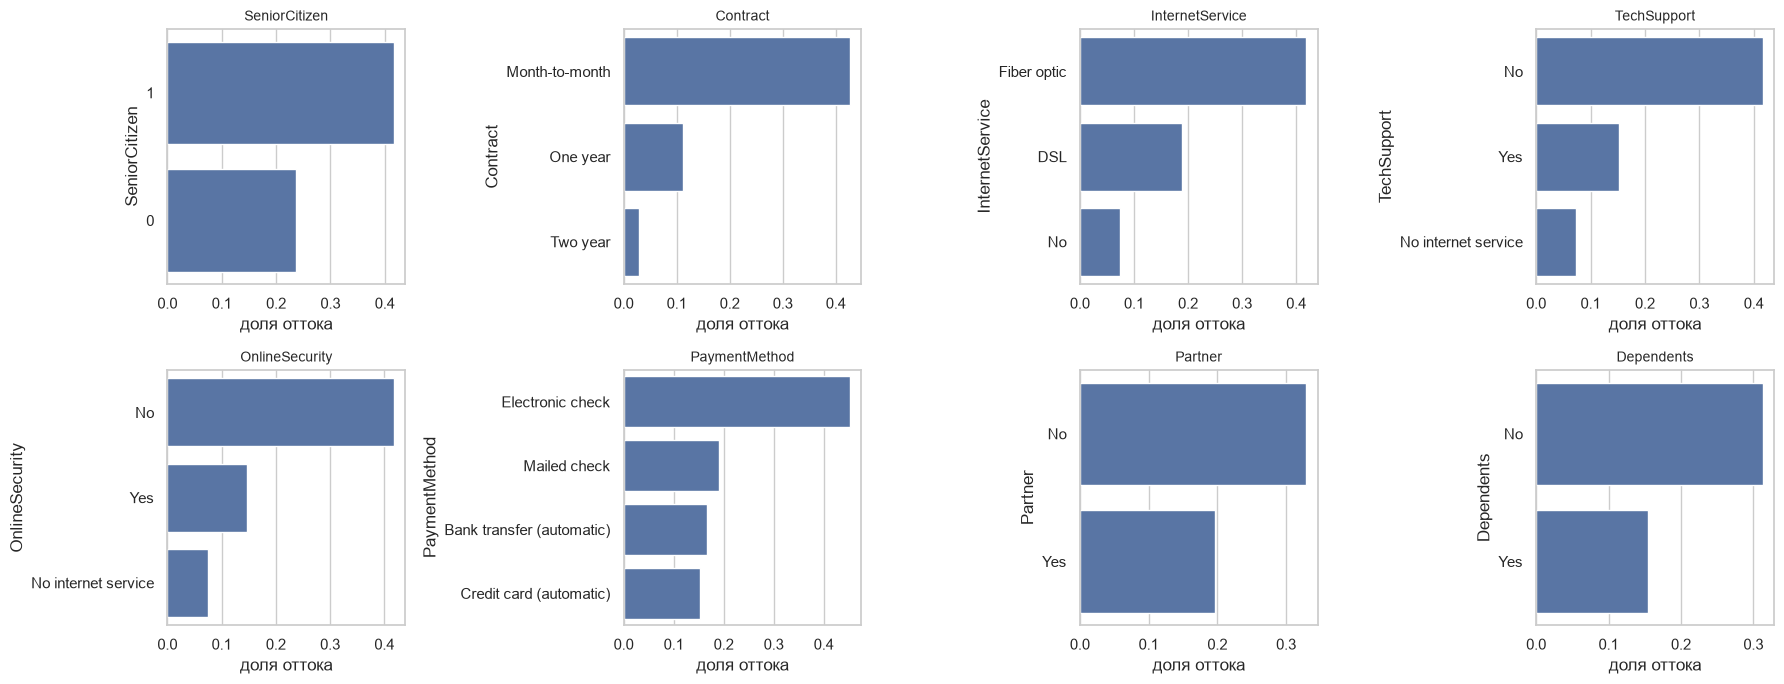

In [14]:
# Доля оттока внутри категорий ключевых признаков
key_cat = ['SeniorCitizen', 'Contract', 'InternetService', 'TechSupport', 'OnlineSecurity',
           'PaymentMethod', 'Partner', 'Dependents']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, key_cat):
    rate = (df.groupby(col, observed=True)['Churn']
              .apply(lambda s: (s == 'Yes').mean())
              .sort_values(ascending=False))
    sns.barplot(x=rate.values, y=rate.index.astype(str), ax=ax).set_title(col, fontsize=10)
    ax.set_xlabel('доля оттока')
plt.tight_layout()
plt.show()

### **Наблюдения:** отток сильнее всего связан с типом контракта (помесячные — до ~43%, двухлетние — ~3%), отсутствием поддержки/безопасности, оплатой electronic check и отсутствием партнёра/иждивенцев. Fiber optic как тип интернета тоже выделяется высоким оттоком.

---

## 6. Связи между признаками

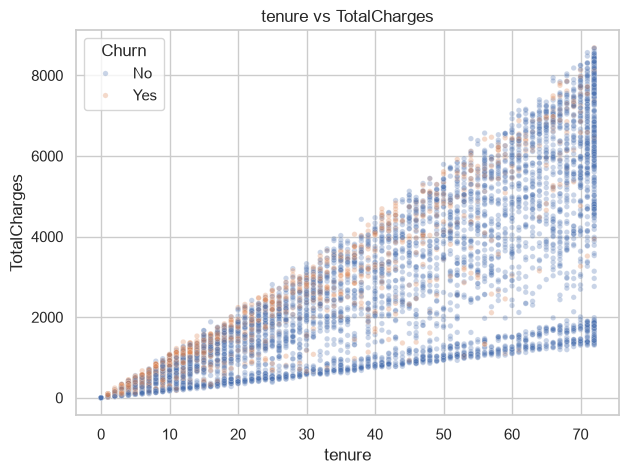

In [15]:
# Диаграмма рассеяния: срок жизни vs суммарные начисления
plt.figure(figsize=(7, 5))
sns.scatterplot(x='tenure', y='TotalCharges', hue='Churn', data=df, alpha=0.3, s=15)
plt.title('tenure vs TotalCharges')
plt.show()

`TotalCharges` почти линейно растёт с `tenure` — признаки избыточны, возможна мультиколлинеарность.

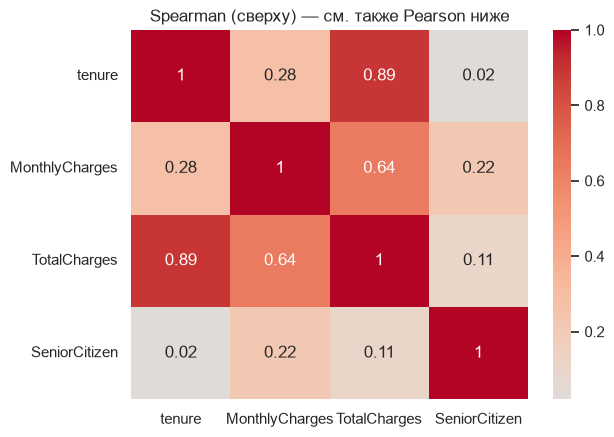

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


In [16]:
# Корреляции Spearman и Pearson для числовых признаков
corr = df[num_cols + ['SeniorCitizen']].corr(method='spearman').round(2)
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Spearman (сверху) — см. также Pearson ниже')
plt.show()
print(df[num_cols].corr(method='pearson').round(2))

<>:9: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:9: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\55873\AppData\Local\Temp\ipykernel_43316\450078805.py:9: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.title('Матрица корреляций $\phi_k$')


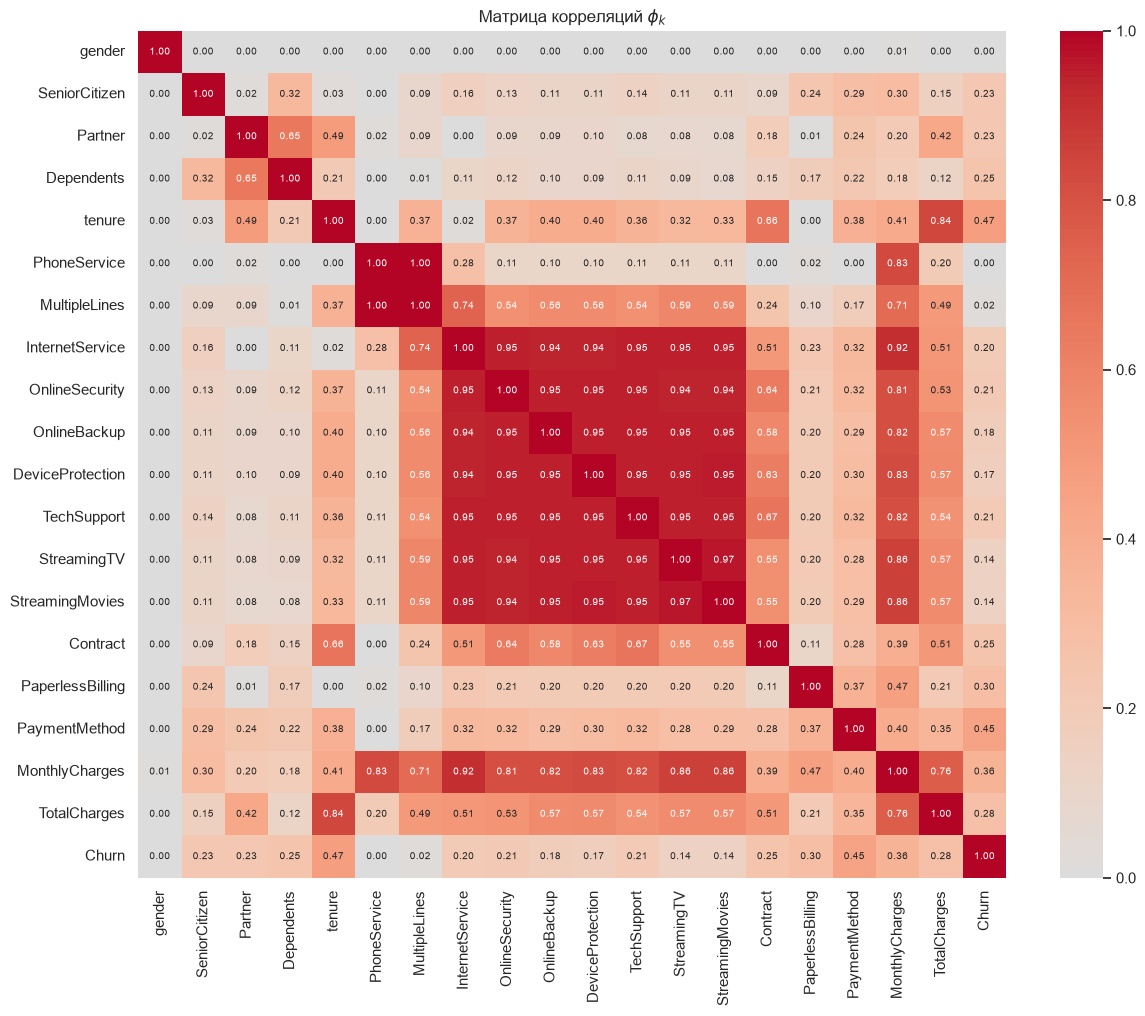

In [17]:
# Матрица phi-k для смешанных типов данных
import phik

interval_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
phik_matrix = df.drop(columns='customerID').phik_matrix(interval_cols=interval_cols)
plt.figure(figsize=(14, 11))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            annot_kws={'size': 7})
plt.title('Матрица корреляций $\phi_k$')
plt.show()

### **Наблюдения:**
- `tenure`–`TotalCharges`: сильная связь (~0,83 Spearman) — признаки дублируют друг друга, при моделировании можно оставить один или применять регуляризацию.
- `Churn` по φk сильнее всего связан с `Contract`, `tenure`, `TotalCharges` и `OnlineSecurity`.
- `customerID` из корреляционного анализа исключён (идентификатор, не признак).

---

## 7. Выводы и гипотезы для моделирования

| Наблюдение | Решение по данным | Гипотеза для модели |
|---|---|---|
| 11 пустых `TotalCharges` при `tenure = 0` | Заполнить 0, строки сохранить | Новые клиенты — отдельный сегмент риска |
| Дисбаланс классов 26,5 / 73,5% | Не балансировать на этапе EDA | Использовать ROC-AUC/PR-AUC/F1, при необходимости — взвешивание классов |
| Ушедшие: высокий `MonthlyCharges`, низкий `tenure` | Оставить оба признака | «Дорогие новые» клиенты — главный сегмент оттока |
| Помесячный контракт → отток до ~43% vs ~3% у двухлетних | Признак `Contract` — ключевой | Вероятность ухода резко падает с длительностью контракта |
| Отсутствие TechSupport/OnlineSecurity повышает отток | Сохранить все бинарные услуги | Подключённые сервисные опции — защитные факторы |
| Electronic check и отсутствие Partner/Dependents связаны с оттоком | Сохранить | Платёжный метод и семейный статус — слабые, но рабочие предикторы |
| Сильная связь `tenure`–`TotalCharges` (0,83) | При моделировании оставить один или регуляризовать | Избежать мультиколлинеарности |
| Выбросы числовых признаков смысловые | Не удалять | — |

**Ограничения:** связь признаков с оттоком — ассоциативная, не причинная; выборка — срез одного оператора, перенос на другие рынки требует проверки. Спорное решение (заполнение нулями) зафиксировано в `docs/eda-plan.md` и подлежит перепроверке на этапе бейзлайна.

Дополнительно для самопроверки можно прогнать `ydata-profiling`; бейзлайн строится после следующего занятия.